  H3: Comparative Analysis — ICU Type Differences

  1. STRUCTURAL COMPARISON: Optimal k and Silhouette Scores
------------------------------------------------------------
  Care Type        Optimal k   Silhouette        n
------------------------------------------------------------
  Adult ICUs               2       0.5379     1096
  PICU                     2       0.6578     1096
  NICU                     3       0.5888     1096

  Key finding: Adults and PICU share a bimodal structure (k=2),
  while NICU requires three clusters (k=3), indicating a more
  complex operational regime landscape in neonatal care.


  2. CLUSTER PROFILES COMPARISON
------------------------------------------------------------

  Adult ICUs (k = 2):
   Cluster      n       %     Sil    Util   Slack   Staff   Space   Mater
  ---------------------------------------------------------------
         0    356   32.5%  0.4639  0.8694  0.1306  0.4039  0.1410  0.0000
         1    740   67.5%  0.5735  0.8441  0.1

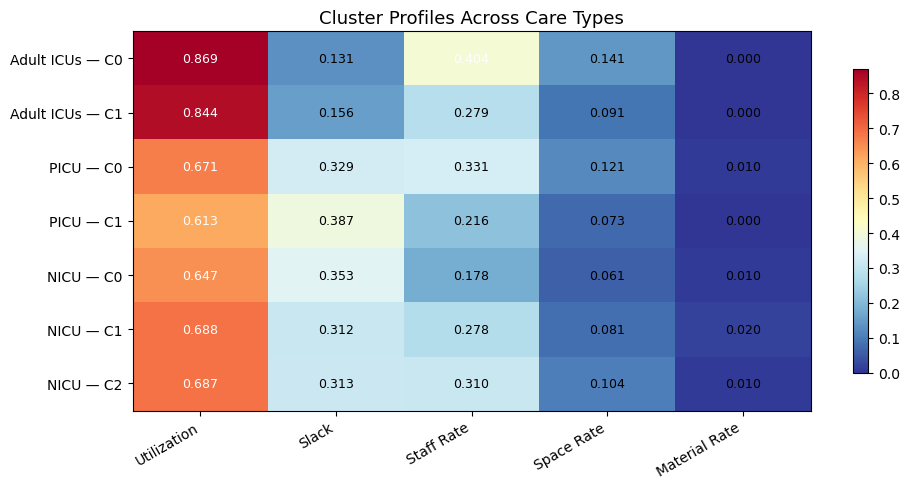

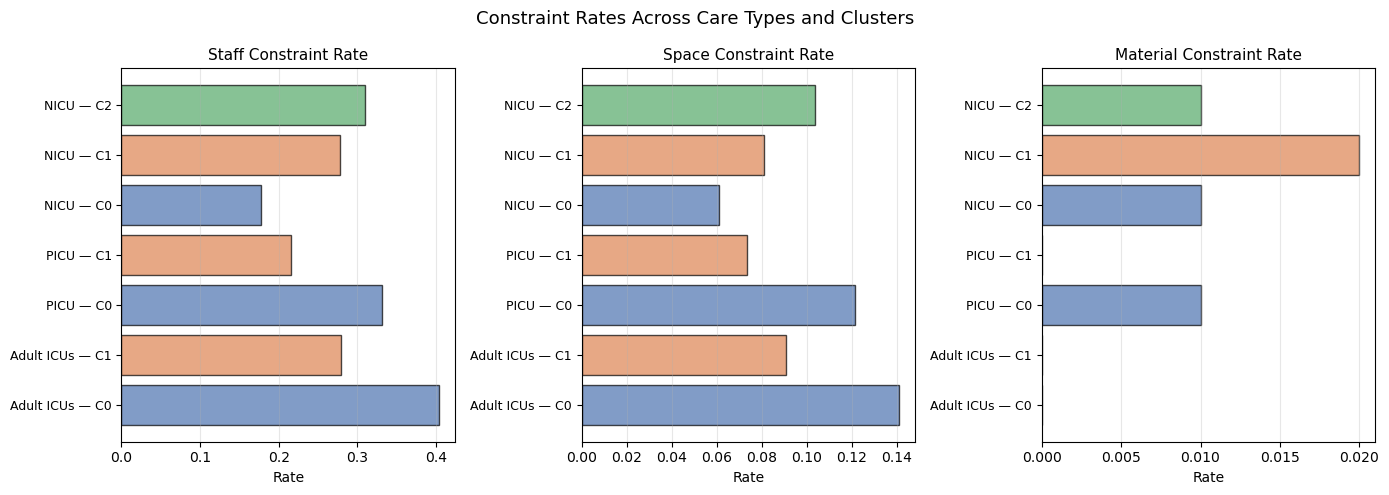

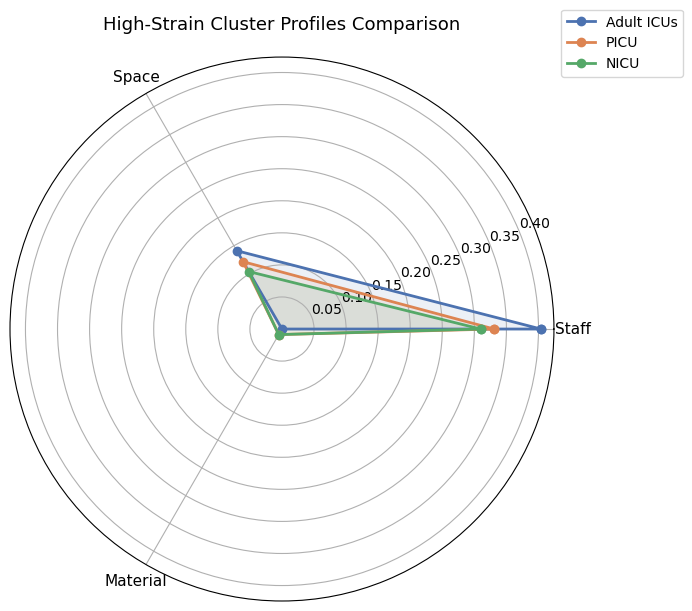


=== H3 Complete ===


In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Load data
# ──────────────────────────────────────────────
df = pd.read_csv('Intensivregister_file.csv', sep=';', decimal=',', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

numeric_cols = ['reporting_units', 'current_covid_cases', 'icu_beds_occupied', 'icu_beds_available',
                'material_constraints', 'staff_constraints', 'space_constraints', 'total_icu_capacity',
                'utilization_rate', 'slack_rate', 'staff_constraint_rate', 'material_constraint_rate',
                'space_constraint_rate', 'utilization_rate_z', 'slack_rate_z',
                'staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# ──────────────────────────────────────────────
# 2. Config per care type
# ──────────────────────────────────────────────
config = {
    'ERWACHSENE': {'label': 'Adult ICUs', 'k': 2},
    'PICU':       {'label': 'PICU',       'k': 2},
    'NICU':       {'label': 'NICU',       'k': 3}
}

features_z = ['staff_constraint_rate_z', 'material_constraint_rate_z', 'space_constraint_rate_z']
report_vars = ['utilization_rate', 'slack_rate', 'staff_constraint_rate',
               'space_constraint_rate', 'material_constraint_rate']
cluster_colors = ['#4C72B0', '#DD8452', '#55A868']

# ──────────────────────────────────────────────
# 3. Cluster all care types and store results
# ──────────────────────────────────────────────
results = {}

for group, cfg in config.items():
    subset = df[df['care_group'] == group].copy()
    subset.reset_index(drop=True, inplace=True)

    X = subset[features_z].values
    k = cfg['k']
    label = cfg['label']

    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    subset['cluster'] = km.fit_predict(X)

    overall_sil = silhouette_score(X, subset['cluster'].values)
    sil_vals = silhouette_samples(X, subset['cluster'].values)
    subset['silhouette'] = sil_vals

    cluster_info = []
    for c in sorted(subset['cluster'].unique()):
        mask = subset['cluster'] == c
        info = {
            'cluster': c,
            'n': mask.sum(),
            'pct': mask.sum() / len(subset) * 100,
            'sil': subset.loc[mask, 'silhouette'].mean(),
            'neg_sil': (subset.loc[mask, 'silhouette'] < 0).sum(),
        }
        for v in report_vars:
            info[f'{v}_mean'] = subset.loc[mask, v].mean()
            info[f'{v}_sd'] = subset.loc[mask, v].std()
        cluster_info.append(info)

    results[group] = {
        'label': label,
        'k': k,
        'n': len(subset),
        'overall_sil': overall_sil,
        'clusters': cluster_info,
        'data': subset
    }

# ──────────────────────────────────────────────
# 4. Structural comparison
# ──────────────────────────────────────────────
print("=" * 70)
print("  H3: Comparative Analysis — ICU Type Differences")
print("=" * 70)

print("\n  1. STRUCTURAL COMPARISON: Optimal k and Silhouette Scores")
print("-" * 60)
print(f"  {'Care Type':<15} {'Optimal k':>10} {'Silhouette':>12} {'n':>8}")
print("-" * 60)
for group, res in results.items():
    print(f"  {res['label']:<15} {res['k']:>10} {res['overall_sil']:>12.4f} {res['n']:>8}")

print(f"\n  Key finding: Adults and PICU share a bimodal structure (k=2),")
print(f"  while NICU requires three clusters (k=3), indicating a more")
print(f"  complex operational regime landscape in neonatal care.")

# ──────────────────────────────────────────────
# 5. Cluster profiles comparison
# ──────────────────────────────────────────────
print(f"\n\n  2. CLUSTER PROFILES COMPARISON")
print("-" * 60)

for group, res in results.items():
    print(f"\n  {res['label']} (k = {res['k']}):")
    print(f"  {'Cluster':>8} {'n':>6} {'%':>7} {'Sil':>7} {'Util':>7} {'Slack':>7} {'Staff':>7} {'Space':>7} {'Mater':>7}")
    print(f"  {'-'*63}")
    for cl in res['clusters']:
        print(f"  {cl['cluster']:>8} {cl['n']:>6} {cl['pct']:>6.1f}% {cl['sil']:>7.4f} "
              f"{cl['utilization_rate_mean']:>7.4f} {cl['slack_rate_mean']:>7.4f} "
              f"{cl['staff_constraint_rate_mean']:>7.4f} {cl['space_constraint_rate_mean']:>7.4f} "
              f"{cl['material_constraint_rate_mean']:>7.4f}")

# ──────────────────────────────────────────────
# 6. Dominant constraint comparison
# ──────────────────────────────────────────────
print(f"\n\n  3. DOMINANT CONSTRAINT COMPARISON")
print("-" * 60)

for group, res in results.items():
    print(f"\n  {res['label']}:")
    for cl in res['clusters']:
        staff = cl['staff_constraint_rate_mean']
        space = cl['space_constraint_rate_mean']
        material = cl['material_constraint_rate_mean']
        dominant = max([('Staff', staff), ('Space', space), ('Material', material)], key=lambda x: x[1])
        print(f"    Cluster {cl['cluster']}: Dominant constraint = {dominant[0]} ({dominant[1]:.4f}), "
              f"Staff={staff:.4f}, Space={space:.4f}, Material={material:.4f}")

# ──────────────────────────────────────────────
# 7. Cross-type interpretation
# ──────────────────────────────────────────────
print(f"\n\n  4. CROSS-TYPE INTERPRETATION")
print("-" * 60)

# Utilization comparison
print(f"\n  Utilization levels:")
for group, res in results.items():
    means = [cl['utilization_rate_mean'] for cl in res['clusters']]
    print(f"    {res['label']}: range {min(means):.4f} — {max(means):.4f}")

adult_high = max(results['ERWACHSENE']['clusters'], key=lambda x: x['staff_constraint_rate_mean'])
picu_high = max(results['PICU']['clusters'], key=lambda x: x['staff_constraint_rate_mean'])
nicu_high = max(results['NICU']['clusters'], key=lambda x: x['staff_constraint_rate_mean'])

print(f"\n  Staff constraint in high-strain regimes:")
print(f"    Adult ICUs: {adult_high['staff_constraint_rate_mean']:.4f}")
print(f"    PICU:       {picu_high['staff_constraint_rate_mean']:.4f}")
print(f"    NICU:       {nicu_high['staff_constraint_rate_mean']:.4f}")

print(f"\n  Material constraint relevance:")
adult_mat = max(cl['material_constraint_rate_mean'] for cl in results['ERWACHSENE']['clusters'])
picu_mat = max(cl['material_constraint_rate_mean'] for cl in results['PICU']['clusters'])
nicu_mat = max(cl['material_constraint_rate_mean'] for cl in results['NICU']['clusters'])
print(f"    Adult ICUs: {adult_mat:.4f} (negligible)")
print(f"    PICU:       {picu_mat:.4f}")
print(f"    NICU:       {nicu_mat:.4f} (highest — distinct material-driven regime)")

print(f"\n  Summary:")
print(f"    - Adults operate under chronic high utilization (~85%) with staff as dominant constraint.")
print(f"    - PICU and NICU operate at lower utilization (~63-69%) but face diverse constraint profiles.")
print(f"    - NICU uniquely requires 3 clusters, reflecting a material constraint dimension")
print(f"      absent in adult and pediatric care.")
print(f"    - Staff shortages are the universal dominant constraint across all care types.")
print(f"    - These structural differences confirm H3: operational stress regimes differ")
print(f"      systematically across ICU types.")

# ──────────────────────────────────────────────
# 8. PLOT — Heatmap: cluster means across care types
# ──────────────────────────────────────────────
heatmap_data = []
heatmap_labels = []

for group, res in results.items():
    for cl in res['clusters']:
        row_label = f"{res['label']} — C{cl['cluster']}"
        heatmap_labels.append(row_label)
        heatmap_data.append([
            cl['utilization_rate_mean'],
            cl['slack_rate_mean'],
            cl['staff_constraint_rate_mean'],
            cl['space_constraint_rate_mean'],
            cl['material_constraint_rate_mean']
        ])

heatmap_cols = ['Utilization', 'Slack', 'Staff Rate', 'Space Rate', 'Material Rate']
heatmap_df = pd.DataFrame(heatmap_data, index=heatmap_labels, columns=heatmap_cols)

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heatmap_df.values, cmap='RdYlBu_r', aspect='auto')

ax.set_xticks(range(len(heatmap_cols)))
ax.set_xticklabels(heatmap_cols, fontsize=10, rotation=30, ha='right')
ax.set_yticks(range(len(heatmap_labels)))
ax.set_yticklabels(heatmap_labels, fontsize=10)

for i in range(len(heatmap_labels)):
    for j in range(len(heatmap_cols)):
        val = heatmap_df.values[i, j]
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=9,
                color='white' if val > 0.4 else 'black')

plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Cluster Profiles Across Care Types', fontsize=13)
plt.tight_layout()
plt.savefig('H3_heatmap_cluster_profiles.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 9. PLOT — Grouped bar chart: constraint rates
# ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
constraint_vars = ['staff_constraint_rate', 'space_constraint_rate', 'material_constraint_rate']
constraint_labels = ['Staff Constraint Rate', 'Space Constraint Rate', 'Material Constraint Rate']

for ax, var, title in zip(axes, constraint_vars, constraint_labels):
    x = np.arange(len(heatmap_labels))
    vals = [row[constraint_vars.index(var) + 2] for row in heatmap_data]  # offset by 2 (util, slack)
    colors = []
    for group, res in results.items():
        for cl in res['clusters']:
            colors.append(cluster_colors[cl['cluster']])

    ax.barh(x, vals, color=colors, alpha=0.7, edgecolor='black')
    ax.set_yticks(x)
    ax.set_yticklabels(heatmap_labels, fontsize=9)
    ax.set_xlabel('Rate', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.3, axis='x')

plt.suptitle('Constraint Rates Across Care Types and Clusters', fontsize=13)
plt.tight_layout()
plt.savefig('H3_constraint_comparison.png', dpi=150)
plt.show()

# ──────────────────────────────────────────────
# 10. PLOT — Radar chart per care type (high-strain clusters)
# ──────────────────────────────────────────────
radar_vars = ['staff_constraint_rate', 'space_constraint_rate', 'material_constraint_rate']
radar_labels = ['Staff', 'Space', 'Material']

# Get high-strain cluster for each care type
high_strain = {
    'Adult ICUs': adult_high,
    'PICU': picu_high,
    'NICU': nicu_high
}

angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
angles += angles[:1]

care_colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for i, (care_label, cl) in enumerate(high_strain.items()):
    values = [cl[f'{v}_mean'] for v in radar_vars]
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, color=care_colors[i], label=care_label)
    ax.fill(angles, values, alpha=0.1, color=care_colors[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels, fontsize=11)
ax.set_title('High-Strain Cluster Profiles Comparison', fontsize=13, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=10)
plt.tight_layout()
plt.savefig('H3_radar_high_strain.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== H3 Complete ===")

In [3]:
# Summary table for thesis
print("\n=== Summary Table for Thesis ===\n")
print(f"{'Care Type':<12} {'k':>3} {'Sil':>6} {'Dominant Constraint':<22} {'Util Range':<15} {'Material Role':<20}")
print("-" * 80)
for group, res in results.items():
    means = [cl['utilization_rate_mean'] for cl in res['clusters']]
    mat = max(cl['material_constraint_rate_mean'] for cl in res['clusters'])
    mat_role = 'Negligible' if mat < 0.002 else 'Moderate' if mat < 0.01 else 'Distinct regime'
    print(f"{res['label']:<12} {res['k']:>3} {res['overall_sil']:>6.4f} {'Staff':22} "
          f"{min(means):.3f}–{max(means):.3f}     {mat_role:<20}")


=== Summary Table for Thesis ===

Care Type      k    Sil Dominant Constraint    Util Range      Material Role       
--------------------------------------------------------------------------------
Adult ICUs     2 0.5379 Staff                  0.844–0.869     Negligible          
PICU           2 0.6578 Staff                  0.613–0.671     Moderate            
NICU           3 0.5888 Staff                  0.647–0.688     Distinct regime     
